<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week3_Miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
files.upload()

Saving Apple Stock Prices From 1981 to 2023.zip to Apple Stock Prices From 1981 to 2023.zip


{'Apple Stock Prices From 1981 to 2023.zip': b'PK\x03\x04-\x00\x00\x00\x08\x00\x98l=V\xe3f\xf5\xbf\xff\xff\xff\xff\xff\xff\xff\xff%\x00\x14\x00Apple Stock Prices (1981 to 2023).csv\x01\x00\x10\x002\xda\n\x00\x00\x00\x00\x00\x8b6\x03\x00\x00\x00\x00\x00\x9c}\xcb\x8e.=\xaf\xd6\x1ci\xdd\x03\x17\xd0b\xe7\x9c\xca\x10\xc1\x80\x01\x123\xe6Hlq\xd0\x86\x8d\x04\x88\xdb\xc7\xae\xd8\x8f\xe3T\xaa\xdf^\xfd\x0f\xfe\xceW\xab\xcao\x0e\xb6\xe38\xf6\xe3\x7f\xfb\x9f\xfe\xcf?~\xfd\x87\xff\xf5\x8f\xff\xf3\xeb\xdf\xfd\xb7\xff\xf2_\xbf\xfe\xfd?\xff\xbf\xaf\x7f\xf3O\xff\xfc\xbf\xff\xf1\xeb_\xff\xe7\xff\xfe/g\xeb?\xfe\xf3?\xfd\xdf\xff\xf1\x8f\x7f\xfeEH\xff\x10\xe2?\xc4q\xc5\xaf\xf0\xafb-!^w\xa3\xc6\\\xfc\x13m\xd0\xbbe|\xa5\xd8Z\xb8B \n\xd5Q\x88)]\xbe\x11Z_\xff\xc6\x9eJ\xf9\xca\xb5\'\xfa\x9c\xbfo\xeb\xf7\xa5\xd4\xbc5\xf2\xe8\xd95b\n9}\x95\x1a\xebUn\n}\xa5\x90\xaf<\xb2o\xf4+W\xd7\x08=\xd5\xf6Uk\xbb\xda\xa4p9\n\xb5\x85\xbc5B\xa9\xae\x11j\xb8\xeaW\x1eW\xea\xe9\xa60\xdc(R\x1ac6\xae\xda\xb7\'\xd2\xa0Nd\x9aF"xOCL/\x04

In [2]:
!unzip Apple\ Stock\ Prices\ From\ 1981\ to\ 2023.zip

Archive:  Apple Stock Prices From 1981 to 2023.zip
  inflating: Apple Stock Prices (1981 to 2023).csv  


In [3]:
import pandas as pd
import numpy as np

# Load the dataset correctly using pandas
apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')

# Display the first few rows
display(apple_stock.head())
apple_stock.info()


,Date,Open,High,Low,Close,Adj Close,Volume
0,02/01/1981,0.154018,0.155134,0.154018,0.154018,0.119849,21660800
1,05/01/1981,0.151228,0.151228,0.150670,0.150670,0.117244,35728000
2,06/01/1981,0.144531,0.144531,0.143973,0.143973,0.112032,45158400
3,07/01/1981,0.138393,0.138393,0.137835,0.137835,0.107256,55686400
4,08/01/1981,0.135603,0.135603,0.135045,0.135045,0.105085,39827200


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10608 entries, 0 to 10607
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10608 non-null  object 
 1   Open       10608 non-null  float64
 2   High       10608 non-null  float64
 3   Low        10608 non-null  float64
 4   Close      10608 non-null  float64
 5   Adj Close  10608 non-null  float64
 6   Volume     10608 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 580.3+ KB


Date range: 1981-01-02 00:00:00 to 2023-01-27 00:00:00
Total trading days: 10608

Most common interval between records:
Date
1 days    8317
3 days    1927
4 days     265
Name: count, dtype: int64


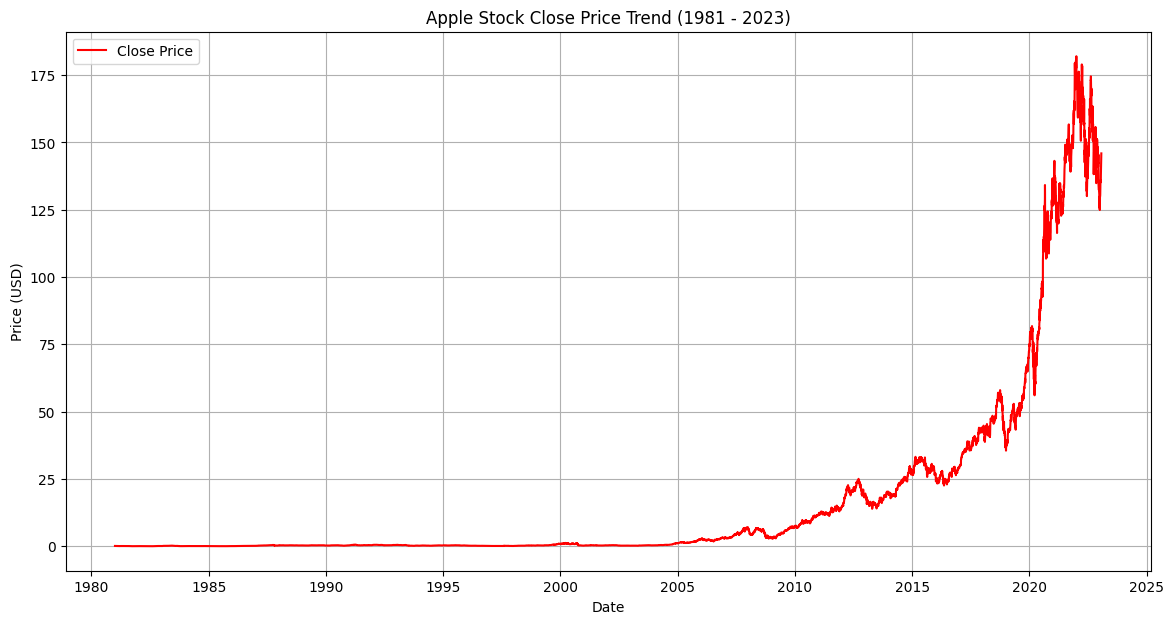

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')

apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')

# Sort the values chronologically
apple_stock = apple_stock.sort_values('Date').reset_index(drop=True)

#index for time series analysis
apple_stock.set_index('Date', inplace=True)

# basic time series features
print("Date range:", apple_stock.index.min(), "to", apple_stock.index.max())
print("Total trading days:", len(apple_stock))

# check typical spacing (frequency)
time_diffs = apple_stock.index.to_series().diff()
print("\nMost common interval between records:")
print(time_diffs.value_counts().head(3))

# Plot the historical trend
plt.figure(figsize=(14, 7))
plt.plot(apple_stock['Close'], label='Close Price', color='red')
plt.title('Apple Stock Close Price Trend (1981 - 2023)')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.grid(True)
plt.legend()
plt.show()

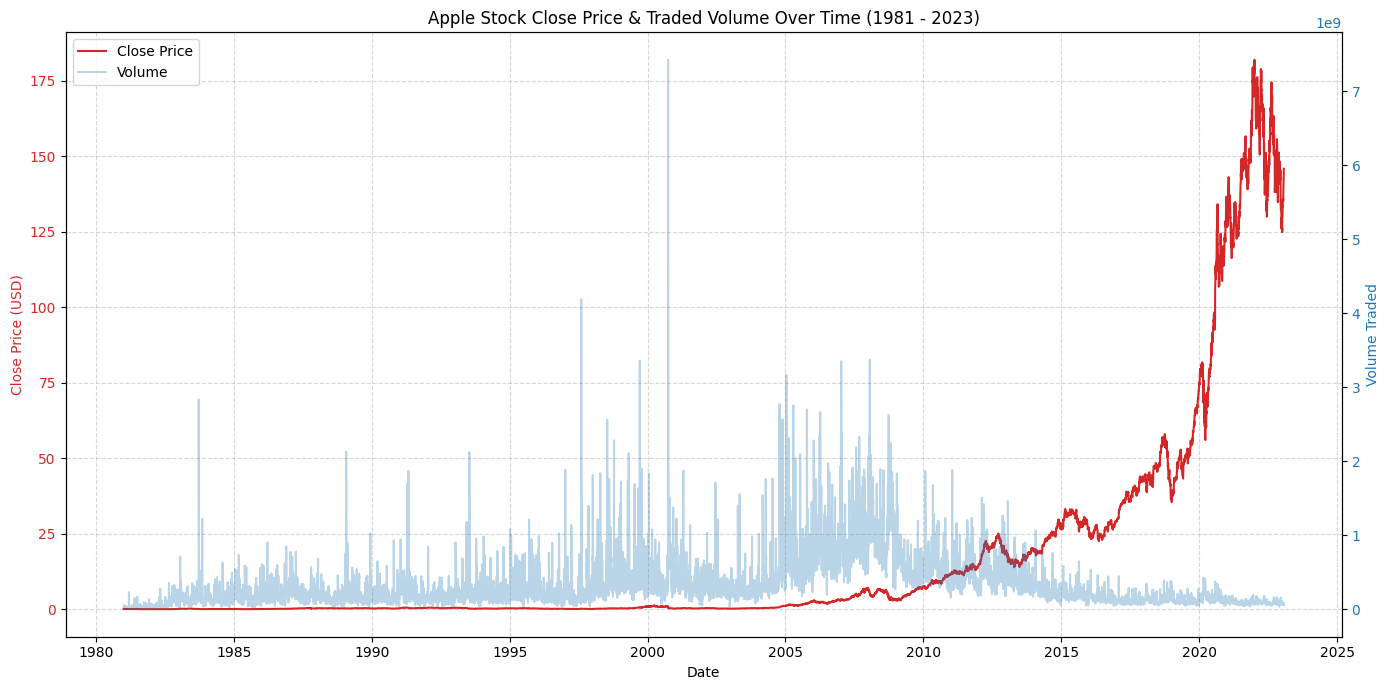

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')
apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')

# Sort the values chronologically and set the index
apple_stock = apple_stock.sort_values('Date').reset_index(drop=True)
apple_stock.set_index('Date', inplace=True)

# Create a plot with two different y-axes
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot the Closing Price on the first y-axis (left)
color = 'tab:red'
ax1.set_xlabel('Date')
ax1.set_ylabel('Close Price (USD)', color=color)
line1 = ax1.plot(apple_stock['Close'], color=color, label='Close Price')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Create a second y-axis that shares the same x-axis for Volume
ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Volume Traded', color=color)
line2 = ax2.plot(apple_stock['Volume'], color=color, alpha=0.3, label='Volume')
ax2.tick_params(axis='y', labelcolor=color)

# Combine the legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Apple Stock Close Price & Traded Volume Over Time (1981 - 2023)')
fig.tight_layout()
plt.show()

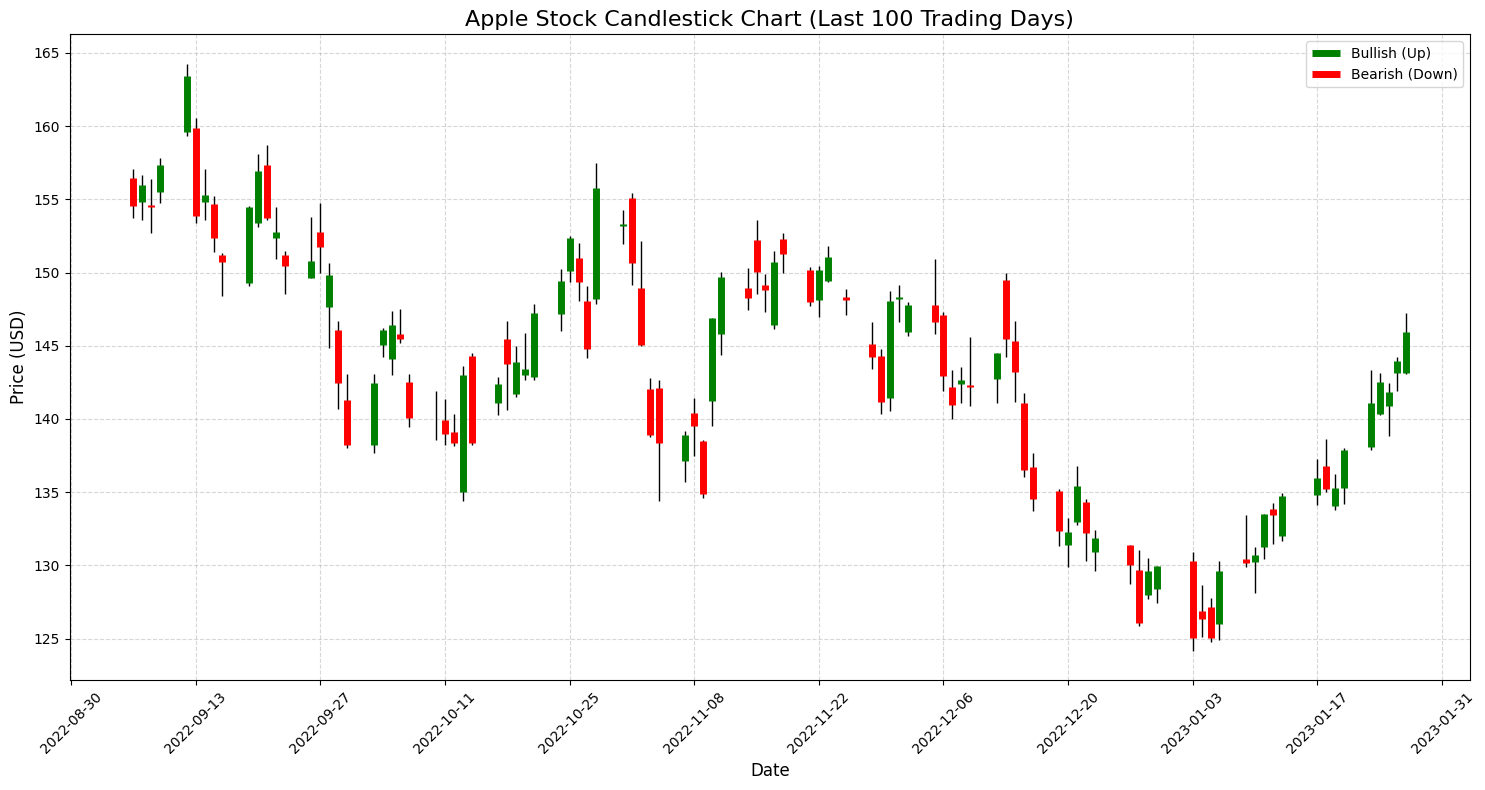

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')
apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')
apple_stock = apple_stock.sort_values('Date').reset_index(drop=True)

zoom_df = apple_stock.tail(100).copy()

# Create the plot
fig, ax = plt.subplots(figsize=(15, 8))

# Define colors for UP and DOWN days
colors_up = zoom_df['Close'] >= zoom_df['Open']
colors_down = zoom_df['Close'] < zoom_df['Open']

# 1. Plot the shadows (High to Low lines)
ax.vlines(zoom_df['Date'], zoom_df['Low'], zoom_df['High'], color='black', linewidth=1)

# 2. Plot the candlestick bodies (Open to Close)
# Green bodies for positive days
ax.vlines(zoom_df.loc[colors_up, 'Date'],
          zoom_df.loc[colors_up, 'Open'],
          zoom_df.loc[colors_up, 'Close'],
          color='green', linewidth=5, label='Bullish (Up)')

# Red bodies for negative days
ax.vlines(zoom_df.loc[colors_down, 'Date'],
          zoom_df.loc[colors_down, 'Open'],
          zoom_df.loc[colors_down, 'Close'],
          color='red', linewidth=5, label='Bearish (Down)')

# Formatting the dates on the X-axis
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2)) # Tick every 2 weeks
plt.xticks(rotation=45)

# Labels and titles
plt.title('Apple Stock Candlestick Chart (Last 100 Trading Days)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Remove duplicate labels in legend
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
import numpy as np

apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')
mean_stock_price = apple_stock['Close'].mean()
median_stock_price = apple_stock['Close'].median()
std_stock_price = apple_stock['Close'].std()

print(f"Mean Stock Price: ${mean_stock_price:.2f}")
print(f"Median Stock Price: ${median_stock_price:.2f}")
print(f"Standard Deviation of Stock Price: ${std_stock_price:.2f}")

Mean Stock Price: $16.70
Median Stock Price: $0.49
Standard Deviation of Stock Price: $35.47


In [10]:
import pandas as pd
import numpy as np

# Convert Date to datetime format first to enable the .dt accessor
apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')

# Group by year and calculate the mean for each year
yearly_means = apple_stock.groupby(apple_stock['Date'].dt.year)['Close'].mean()

# Calculate overall statistics across the yearly averages
mean_by_year = np.mean(yearly_means)
median_by_year = np.median(yearly_means)
std_by_year = np.std(yearly_means)

print(f"Mean Stock Price by Year: ${mean_by_year:.2f}")
print(f"Median Stock Price by Year: ${median_by_year:.2f}")
print(f"Standard Deviation of Stock Price by Year: ${std_by_year:.2f}")

Mean Stock Price by Year: $19.28
Median Stock Price by Year: $0.52
Standard Deviation of Stock Price by Year: $38.79


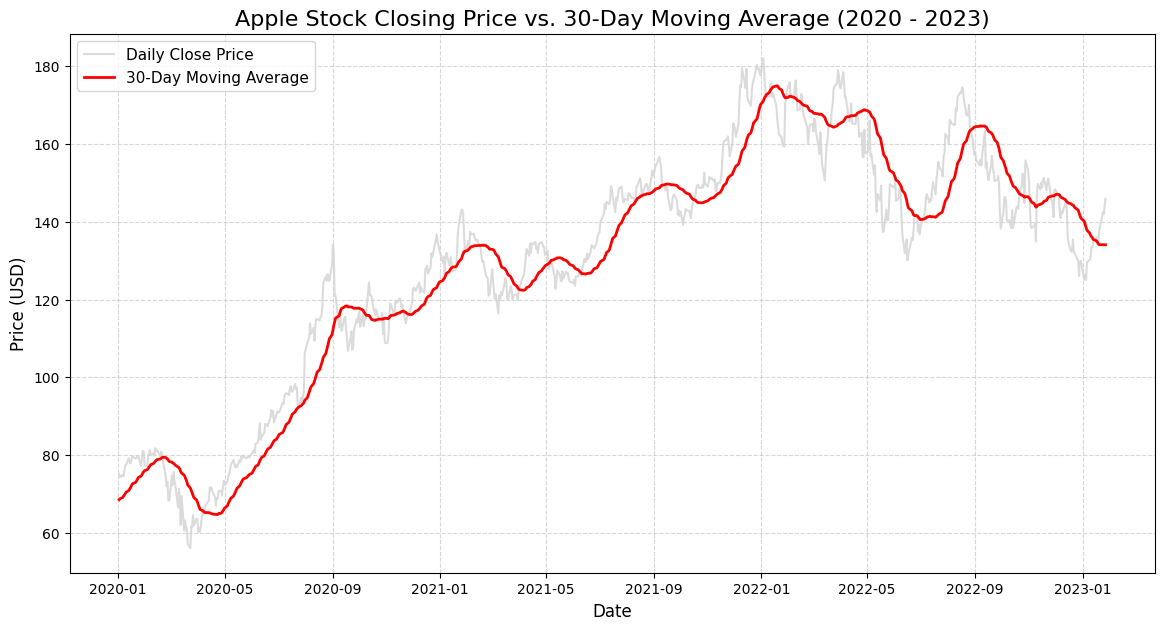

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare data
apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')
apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')
apple_stock = apple_stock.sort_values('Date').reset_index(drop=True)
apple_stock.set_index('Date', inplace=True)

# Calculate the 30-day moving average
apple_stock['Close_30MA'] = apple_stock['Close'].rolling(window=30).mean()

recent_data = apple_stock.loc['2020':'2023']

# Plot the results
plt.figure(figsize=(14, 7))
plt.plot(recent_data['Close'], label='Daily Close Price', color='lightgray', alpha=0.8)
plt.plot(recent_data['Close_30MA'], label='30-Day Moving Average', color='red', linewidth=2)

plt.title('Apple Stock Closing Price vs. 30-Day Moving Average (2020 - 2023)', fontsize=16)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

In [17]:
import pandas as pd
import numpy as np
from scipy import stats

apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')
apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')
apple_stock = apple_stock.sort_values('Date').reset_index(drop=True)
apple_stock.set_index('Date', inplace=True)

# Extract closing prices for two specific years to compare (e.g., 2021 vs 2022)
prices_2021 = apple_stock.loc['2021', 'Close']
prices_2022 = apple_stock.loc['2022', 'Close']

print(f"2021 - Mean: ${prices_2021.mean():.2f}, Std Dev: ${prices_2021.std():.2f}, N: {len(prices_2021)}")
print(f"2022 - Mean: ${prices_2022.mean():.2f}, Std Dev: ${prices_2022.std():.2f}, N: {len(prices_2022)}\n")

# Perform an Independent Samples t-test (assuming unequal variances with Welch's t-test)
t_stat, p_val = stats.ttest_ind(prices_2021, prices_2022, equal_var=False)

print("--- T-Test Results ---")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4e}")

# Interpret the results
alpha = 0.05
if p_val < alpha:
    print("\nResult: Statistically Significant (Reject Null Hypothesis).")
    print("There is a significant difference between the average closing prices of 2021 and 2022.")
else:
    print("\nResult: Not Statistically Significant (Fail to Reject Null Hypothesis).")
    print("There is no significant difference between the average closing prices of 2021 and 2022.")

2021 - Mean: $140.99, Std Dev: $14.66, N: 252
2022 - Mean: $154.84, Std Dev: $13.06, N: 251

--- T-Test Results ---
T-statistic: -11.1866
P-value: 4.7097e-26

Result: Statistically Significant (Reject Null Hypothesis).
There is a significant difference between the average closing prices of 2021 and 2022.


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

apple_stock = pd.read_csv('Apple Stock Prices (1981 to 2023).csv')
apple_stock['Date'] = pd.to_datetime(apple_stock['Date'], format='%d/%m/%Y')
apple_stock = apple_stock.sort_values('Date').reset_index(drop=True)
apple_stock.set_index('Date', inplace=True)



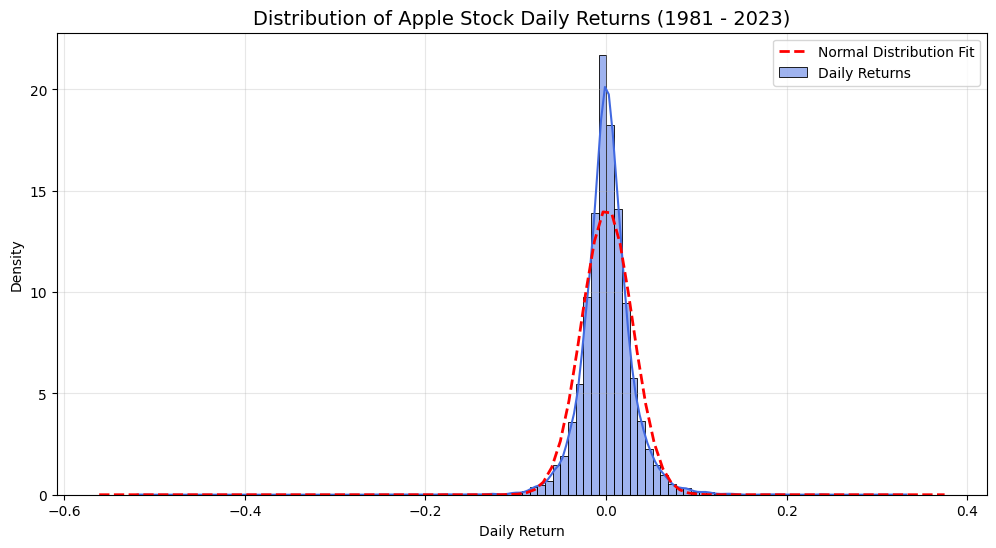

--- Normality Test Results (D'Agostino's K^2) ---
Statistic: 2719.2053
P-value: 0.0000e+00

Result: Reject the Null Hypothesis (Not Normally Distributed).
Daily returns have a distribution that significantly departs from normality (common for financial assets due to fat tails).


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Calculate daily percentage returns from the Close prices
apple_stock['Daily_Return'] = apple_stock['Close'].pct_change()

# Drop the first row since it will be NaN
daily_returns = apple_stock['Daily_Return'].dropna()

# --- 1. Visualizing the Distribution ---
plt.figure(figsize=(12, 6))
sns.histplot(daily_returns, kde=True, bins=100, color='royalblue', label='Daily Returns', stat='density')

# Overlay a theoretical normal distribution for comparison
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, daily_returns.mean(), daily_returns.std())
plt.plot(x, p, 'r--', linewidth=2, label='Normal Distribution Fit')

plt.title("Distribution of Apple Stock Daily Returns (1981 - 2023)", fontsize=14)
plt.xlabel("Daily Return")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- 2. Statistical Normality Test (D'Agostino's K-squared test) ---
stat, p_val = stats.normaltest(daily_returns)

print("--- Normality Test Results (D'Agostino's K^2) ---")
print(f"Statistic: {stat:.4f}")
print(f"P-value: {p_val:.4e}")

# Interpretation using standard alpha = 0.05
alpha = 0.05
if p_val < alpha:
    print("\nResult: Reject the Null Hypothesis (Not Normally Distributed).")
    print("Daily returns have a distribution that significantly departs from normality (common for financial assets due to fat tails).")
else:
    print("\nResult: Fail to Reject the Null Hypothesis (Normally Distributed).")
    print("Daily returns match a normal distribution.")